<a href="https://colab.research.google.com/github/LennardBehmann/Intro-ML/blob/main/Homework_6/ML_HW6_P1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Homework 6 Problem 1 - neuronal networks

**import libraries **

In [74]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

import torch.nn as nn
import torch.optim as optim

**import dataset from github**

In [75]:
import pandas as pd

url = 'https://raw.githubusercontent.com/LennardBehmann/Intro-ML/refs/heads/main/Homework_6/Housing.csv'

df = pd.read_csv(url)

display(df.head())

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


**convert yes/no to binary values**

In [76]:
df_float = df.copy()
binary_columns = [
    'mainroad',
    'guestroom',
    'basement',
    'hotwaterheating',
    'airconditioning',
    'prefarea'
]
for column in binary_columns:
    df_float[column] = df_float[column].map({'yes': 1, 'no': 0})

df_float.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,furnished
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,furnished
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,semi-furnished
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,furnished
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,furnished


**furnishing status problem**

In [77]:

df_float['furnishingstatus'] = df_float['furnishingstatus'].map({'unfurnished':0, 'semi-furnished':1, 'furnished':2})
df_float.head()


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,2
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,2
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,2
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,2


**choose features**

In [78]:
features=['area','bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus' ]
X=df_float[features]
y=df['price']
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (545, 12)
y shape: (545,)


In [79]:
print("X shape:", X.shape)
print("y shape:", y.shape)
print("X samples:", len(X))
print("y samples:", len(y))

X shape: (545, 12)
y shape: (545,)
X samples: 545
y samples: 545


**split in 70% train, 15% test, 15% val**
to compare models with val data and only use the test data for the best model with

In [80]:
# Step 1: 70% Training, 30% Rest
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42
)

# Step 2: Rest in Validation und Test aufteilen
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42
)

print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("X_val shape:", X_val.shape)
print("y_train shape:", y_train.shape)
print("y_test shape:", y_test.shape)
print("y_val shape:", y_val.shape)

X_train shape: (381, 12)
X_test shape: (82, 12)
X_val shape: (82, 12)
y_train shape: (381,)
y_test shape: (82,)
y_val shape: (82,)


**Standardise**

In [81]:
# Standardize input features X
scaler_X = StandardScaler()

X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled = scaler_X.transform(X_test)
X_val_scaled = scaler_X.transform(X_val)


# Standardize target values y
scaler_y = StandardScaler()

y_train_scaled = scaler_y.fit_transform(y_train.values.reshape(-1, 1))
y_test_scaled = scaler_y.transform(y_test.values.reshape(-1, 1))
y_val_scaled = scaler_y.transform(y_val.values.reshape(-1,1))

**conversion to tensors**

In [82]:
X_train_tensor = torch.tensor(X_train_scaled, dtype=torch.float32)
X_test_tensor = torch.tensor(X_test_scaled, dtype=torch.float32)
X_val_tensor = torch.tensor(X_val_scaled, dtype=torch.float32)

y_train_tensor = torch.tensor(y_train_scaled, dtype=torch.float32)
y_test_tensor = torch.tensor(y_test_scaled, dtype=torch.float32)
y_val_tensor = torch.tensor(y_val_scaled, dtype=torch.float32)

print("X_train_tensor shape:", X_train_tensor.shape)
print("y_train_tensor shape:", y_train_tensor.shape)
print("X_test_tensor shape:", X_test_tensor.shape)
print("y_test_tensor shape:", y_test_tensor.shape)
print("X_val_tensor shape:", X_val_tensor.shape)
print("y_val_tensor shape:", y_val_tensor.shape)

X_train_tensor shape: torch.Size([381, 12])
y_train_tensor shape: torch.Size([381, 1])
X_test_tensor shape: torch.Size([82, 12])
y_test_tensor shape: torch.Size([82, 1])
X_val_tensor shape: torch.Size([82, 12])
y_val_tensor shape: torch.Size([82, 1])


**Define models**

In [83]:
#model function
def create_model(input_number, output_number, hidden_layers):

    layers = []
    current_size = input_number

    # Create hidden layers
    for neurons in hidden_layers:
        layers.append(nn.Linear(current_size, neurons))
        layers.append(nn.ReLU())

        current_size = neurons

    # Create output layer
    layers.append(nn.Linear(current_size, output_number))

    # Build model
    model = nn.Sequential(*layers)

    return model



In [84]:

# Define model architectures
architectures = {
    "A": [5, 5],
    "B": [2, 2],
    "C": [3, 3, 3],
    "D": [3, 7, 3]
}


In [85]:

# General loss function
loss_fn = nn.MSELoss()

# General optimizer function
def create_optimizer(model, learning_rate=0.005):
    return torch.optim.SGD(
        model.parameters(),
        lr=learning_rate
    )



**train different models (A-D)**

In [86]:

import copy

def train_model(model, optimizer, loss_fn,
                X_train, y_train, X_val, y_val,
                n_epochs=10000, verbose=False):

    train_losses = []
    val_losses = []

    best_val_loss = float("inf")
    best_epoch = 0
    best_weights = None

    for epoch in range(n_epochs):

        # TRAINING
        model.train()

        predictions = model(X_train)
        train_loss = loss_fn(predictions, y_train)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        # VALIDATION
        model.eval()

        with torch.no_grad():
            val_predictions = model(X_val)
            val_loss = loss_fn(val_predictions, y_val)

        # SAVE LOSSES
        train_losses.append(train_loss.item())
        val_losses.append(val_loss.item())

        # SAVE BEST MODEL WEIGHTS
        if val_loss.item() < best_val_loss:
            best_val_loss = val_loss.item()
            best_epoch = epoch + 1
            best_weights = copy.deepcopy(model.state_dict())

        # PRINT EVERY 500 EPOCHS
        if verbose and (epoch + 1) % 500 == 0:
            print(f"Epoch {epoch+1}: "
                  f"Train = {train_loss.item():.4f}, "
                  f"Val = {val_loss.item():.4f}")

    # RESTORE BEST WEIGHTS
    model.load_state_dict(best_weights)

    return train_losses, val_losses, best_val_loss, best_epoch


In [87]:

# Compare architectures, learning rates, and seeds

seeds = [42, 43, 44, 45, 46]
learning_rates = [0.001, 0.005, 0.01]

run_results = {}
summary_rows = []

for name, hidden_layers in architectures.items():

    for lr in learning_rates:

        for seed in seeds:

            # Set seed
            torch.manual_seed(seed)

            # Create new model
            model = create_model(
                input_number=12,
                output_number=1,
                hidden_layers=hidden_layers
            )

            # Create optimizer with selected learning rate
            optimizer = create_optimizer(
                model,
                learning_rate=lr
            )

            # Train model
            train_losses, val_losses, best_val, best_epoch = train_model(
                model,
                optimizer,
                loss_fn,
                X_train_tensor,
                y_train_tensor,
                X_val_tensor,
                y_val_tensor,
                n_epochs=10000,
                verbose=False
            )

            # Save model and loss curves
            run_results[(name, lr, seed)] = {
                "model": model,
                "train_losses": train_losses,
                "val_losses": val_losses,
                "best_epoch": best_epoch
            }

            # Save comparison results
            summary_rows.append({
                "model": name,
                "learning_rate": lr,
                "seed": seed,
                "best_val_loss": best_val,
                "best_epoch": best_epoch
            })

            print(
                f"Model {name} | LR {lr} | "
                f"Seed {seed} | Val Loss {best_val:.4f}"
            )


Model A | LR 0.001 | Seed 42 | Val Loss 0.5346
Model A | LR 0.001 | Seed 43 | Val Loss 0.5406
Model A | LR 0.001 | Seed 44 | Val Loss 0.5884
Model A | LR 0.001 | Seed 45 | Val Loss 0.5391
Model A | LR 0.001 | Seed 46 | Val Loss 0.5712
Model A | LR 0.005 | Seed 42 | Val Loss 0.5346
Model A | LR 0.005 | Seed 43 | Val Loss 0.5355
Model A | LR 0.005 | Seed 44 | Val Loss 0.5665
Model A | LR 0.005 | Seed 45 | Val Loss 0.5169
Model A | LR 0.005 | Seed 46 | Val Loss 0.5549
Model A | LR 0.01 | Seed 42 | Val Loss 0.5346
Model A | LR 0.01 | Seed 43 | Val Loss 0.5355
Model A | LR 0.01 | Seed 44 | Val Loss 0.5665
Model A | LR 0.01 | Seed 45 | Val Loss 0.4973
Model A | LR 0.01 | Seed 46 | Val Loss 0.5549
Model B | LR 0.001 | Seed 42 | Val Loss 0.5471
Model B | LR 0.001 | Seed 43 | Val Loss 0.5934
Model B | LR 0.001 | Seed 44 | Val Loss 0.6228
Model B | LR 0.001 | Seed 45 | Val Loss 0.5417
Model B | LR 0.001 | Seed 46 | Val Loss 0.5959
Model B | LR 0.005 | Seed 42 | Val Loss 0.5452
Model B | LR 0.005

In [88]:

results_df = pd.DataFrame(summary_rows)

summary = (
    results_df.groupby(["model", "learning_rate"])
    .agg(
        mean_val_loss=("best_val_loss", "mean"),
        std_val_loss=("best_val_loss", "std"),
        min_val_loss=("best_val_loss", "min")
    )
    .sort_values("mean_val_loss")
)

display(summary)


mean_val_loss  std_val_loss  min_val_loss
model learning_rate                                           
C     0.010               0.525183      0.023333      0.488338
      0.005               0.533932      0.012754      0.516278
D     0.010               0.537377      0.020553      0.505518
A     0.010               0.537752      0.026300      0.497315
      0.005               0.541673      0.019317      0.516862
B     0.010               0.544538      0.028047      0.506395
      0.005               0.545234      0.027265      0.508165
A     0.001               0.554774      0.023722      0.534637
D     0.005               0.573491      0.070344      0.516661
B     0.001               0.580189      0.034671      0.541749
D     0.001               0.850803      0.395569      0.556402
C     0.001               0.899390      0.432078      0.546498

In [89]:

# Select best architecture and learning rate
best_name, best_lr = summary.index[0]

print(f"Best Model: {best_name}")
print(f"Best Learning Rate: {best_lr}")
print(f"Mean Validation Loss: {summary.iloc[0]['mean_val_loss']:.4f}")

# Select predetermined seed
final_seed = 42

best_run = run_results[(best_name, best_lr, final_seed)]
best_model = best_run["model"]

print(f"Best Epoch: {best_run['best_epoch']}")


Best Model: C
Best Learning Rate: 0.01
Mean Validation Loss: 0.5252
Best Epoch: 7463


In [92]:

# Select best architecture and learning rate
best_name, best_lr = summary.index[0]

# Select a fixed seed
final_seed = 42

# Get the trained model
best_run = run_results[(best_name, best_lr, final_seed)]
best_model = best_run["model"]

print(f"Selected Model: {best_name}")
print(f"Learning Rate: {best_lr}")
print(f"Seed: {final_seed}")
print(f"Best Epoch: {best_run['best_epoch']}")


Selected Model: C
Learning Rate: 0.01
Seed: 42
Best Epoch: 7463


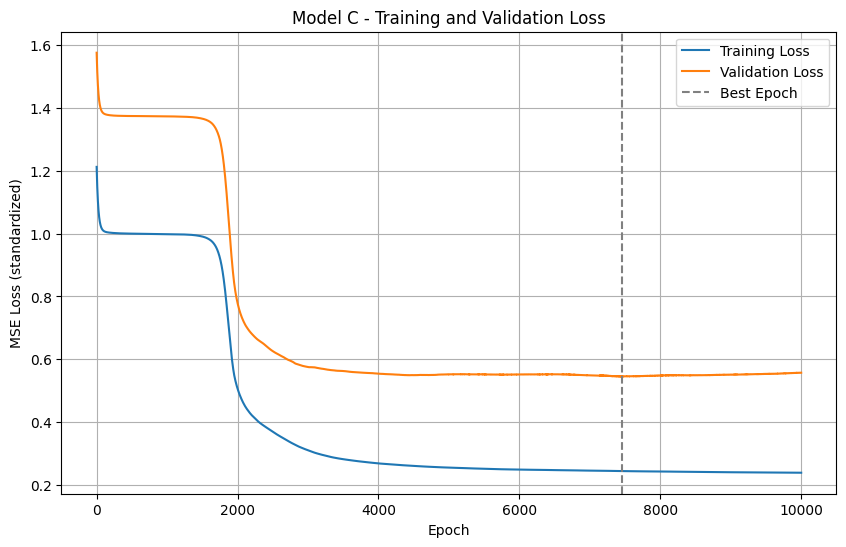

In [93]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.plot(
    best_run["train_losses"],
    label="Training Loss"
)

plt.plot(
    best_run["val_losses"],
    label="Validation Loss"
)

plt.axvline(
    best_run["best_epoch"] - 1,
    color="gray",
    linestyle="--",
    label="Best Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("MSE Loss (standardized)")
plt.title(f"Model {best_name} - Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()


In [94]:

import numpy as np
from sklearn.metrics import mean_squared_error, r2_score

# Final test evaluation
best_model.eval()

with torch.no_grad():
    test_predictions = best_model(X_test_tensor)

# Convert predictions back to original price scale
y_pred = scaler_y.inverse_transform(
    test_predictions.cpu().numpy()
).ravel()

# True housing prices (original scale)
y_true = y_test.to_numpy()

# Evaluation metrics
mse = mean_squared_error(y_true, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_true, y_pred)

print(f"Final Model: {best_name}")
print(f"Final Seed: {final_seed}")
print(f"Test MSE: {mse:.2f}")
print(f"Test RMSE: {rmse:.2f}")
print(f"Test R²: {r2:.4f}")


Final Model: C
Final Seed: 42
Test MSE: 1424644636672.00
Test RMSE: 1193584.78
Test R²: 0.6681


In [95]:

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Create Linear Regression model
linear_model = LinearRegression()

# Train model
linear_model.fit(
    X_train_scaled,
    y_train_scaled.ravel()
)

# Validation predictions
linear_val_pred = linear_model.predict(X_val_scaled)

# Calculate validation MSE
linear_val_mse = mean_squared_error(
    y_val_scaled.ravel(),
    linear_val_pred
)

print(f"Linear Regression Validation MSE: {linear_val_mse:.4f}")


Linear Regression Validation MSE: 0.5718


In [96]:

from sklearn.svm import SVR
import pandas as pd

svr_results = []

for C in [0.1, 1, 10, 100]:
    for epsilon in [0.01, 0.1, 0.2]:

        svr_model = SVR(
            kernel="rbf",
            C=C,
            epsilon=epsilon,
            gamma="scale"
        )

        # Train SVR
        svr_model.fit(
            X_train_scaled,
            y_train_scaled.ravel()
        )

        # Validation predictions
        val_pred = svr_model.predict(X_val_scaled)

        # Validation MSE
        val_mse = mean_squared_error(
            y_val_scaled.ravel(),
            val_pred
        )

        svr_results.append({
            "C": C,
            "epsilon": epsilon,
            "val_mse": val_mse
        })

# Compare results
svr_results_df = pd.DataFrame(svr_results)
svr_results_df = svr_results_df.sort_values("val_mse")

display(svr_results_df)


,C,epsilon,val_mse
5,1.0,0.20,0.510548
4,1.0,0.10,0.517883
3,1.0,0.01,0.525395
8,10.0,0.20,0.604160
7,10.0,0.10,0.607206
6,10.0,0.01,0.633472
11,100.0,0.20,0.682737
0,0.1,0.01,0.689531
1,0.1,0.10,0.693456
10,100.0,0.10,0.698919


In [97]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, r2_score

# Select best SVR based on validation MSE
best_svr_params = svr_results_df.iloc[0]

best_svr = SVR(
    kernel="rbf",
    C=float(best_svr_params["C"]),
    epsilon=float(best_svr_params["epsilon"]),
    gamma="scale"
)

# Train SVR on training data
best_svr.fit(X_train_scaled, y_train_scaled.ravel())

# Predictions on the test set
linear_pred_scaled = linear_model.predict(X_test_scaled)
svr_pred_scaled = best_svr.predict(X_test_scaled)

best_model.eval()
with torch.no_grad():
    nn_pred_scaled = best_model(X_test_tensor).cpu().numpy().ravel()

# Convert predictions to original price scale
linear_pred = scaler_y.inverse_transform(
    linear_pred_scaled.reshape(-1, 1)
).ravel()

svr_pred = scaler_y.inverse_transform(
    svr_pred_scaled.reshape(-1, 1)
).ravel()

nn_pred = scaler_y.inverse_transform(
    nn_pred_scaled.reshape(-1, 1)
).ravel()

# Actual prices
y_true = y_test.to_numpy().ravel()

# General evaluation function
def evaluate_model(name, predictions):
    mse = mean_squared_error(y_true, predictions)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_true, predictions)

    return {
        "Model": name,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }

# Compare test performance
comparison_results = [
    evaluate_model("Neural Network", nn_pred),
    evaluate_model("Linear Regression", linear_pred),
    evaluate_model("SVR", svr_pred)
]

comparison_df = pd.DataFrame(comparison_results)
comparison_df = comparison_df.sort_values("MSE")

display(comparison_df)

print("Best Test Performance:", comparison_df.iloc[0]["Model"])


,Model,MSE,RMSE,R2
1,Linear Regression,1.273676e+12,1.128573e+06,0.703315
0,Neural Network,1.424645e+12,1.193585e+06,0.668149
2,SVR,1.433755e+12,1.197395e+06,0.666026


Best Test Performance: Linear Regression
